# Sunum grafikleri (basit anlatım)

Bu notebook yeni analiz yapmaz. Notebook 01–04'teki bulguları **herkesin anlayacağı basit grafiklerle** gösterir: her
grafik tek bir mesaj verir, başlığı o mesajı düz bir cümleyle söyler. Grafiklerdeki her sayı aşağıdaki kodda hesaplanır ve
yazdırılır; seçim kuralları notebook 01 ve 03 ile aynıdır. Ayrıntılı grafikler ve istatistikler notebook 01–04'tedir.

**Girdi:** `veri/islenmis/` (notebook 01–04'ün çıktıları), `cikti/` tabloları, MAEC ham metni (yalnız metin temizliği örneği için).
**Çıktı:** `sekiller/s01_*.png` … `s12_*.png`.

**Test ayrımı:** oynaklığa (hedefe) dayanan bütün grafikler yalnız geliştirme döneminden (çağrı tarihi ≤ 2016) yapılır;
test döneminden yalnız sayılar ve girdiler (metin, fiyat) kullanılır.

In [1]:
import sys
import textwrap
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

from src import temizle, veri

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
SINIF_RENK = ["#8fbcf0", "#2a78d6", "#104281"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.labelsize": 12,
                     "xtick.labelsize": 11.5, "ytick.labelsize": 11.5, "legend.fontsize": 11})


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


VIRGUL = FuncFormatter(lambda x, _: tr(x) if float(x).is_integer() else f"{x:g}".replace(".", ",").replace("-", "−"))


def basliklar(fig, ana, alt):
    """Kalın başlık = grafiğin tek mesajı; gri alt satır = ne gösterildiği."""
    h = fig.get_size_inches()[1]
    fig.suptitle(ana, x=0.01, y=1 - 0.06 / h, ha="left", va="top", fontsize=15, fontweight="bold", color=KOYU)
    fig.text(0.01, 1 - 0.48 / h, alt, ha="left", va="top", fontsize=11, color="#555555")
    fig.subplots_adjust(top=1 - 1.0 / h)


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


ce = pd.read_parquet(ISLENMIS / "cagrilar_eslesmis.parquet")       # eşleşmiş 3.026 çağrı (temizlik öncesi)
tc = pd.read_parquet(ISLENMIS / "temiz_cagrilar.parquet")          # nihai 3.000 çağrı
e = pd.read_parquet(ISLENMIS / "eda_tablosu.parquet")              # geliştirme dönemi analiz tablosu (1.866)
pen = pd.read_parquet(ISLENMIS / "fiyat_pencereleri.parquet", columns=["klasor", "gun", "adj close", "getiri"])
bolme = pd.read_parquet(ISLENMIS / "bolme.parquet")
print("eşleşmiş:", len(ce), "| nihai:", len(tc), "| geliştirme analiz tablosu:", len(e))

eşleşmiş: 3026 | nihai: 3000 | geliştirme analiz tablosu: 1866


## 1. Veri hunisi: kaç toplantıdan kaçı kaldı?

,adım,düşen,kalan,kalan_%
0,MAEC çağrısı (başlangıç),0,3443,100.0
1,ticker fiyat verisinde yok,411,3032,88.1
2,fiyat serisi çağrı tarihini kapsamıyor,5,3027,87.9
3,60 günlük geçmiş yetersiz,1,3026,87.9
4,içeriksiz metin (≤ 20 kelime) [Faz 2],26,3000,87.1


başlangıç 3443 | eşleşen 3026 | nihai 3000 | fiyatsız 411 | kesik 6 | boş metin 26


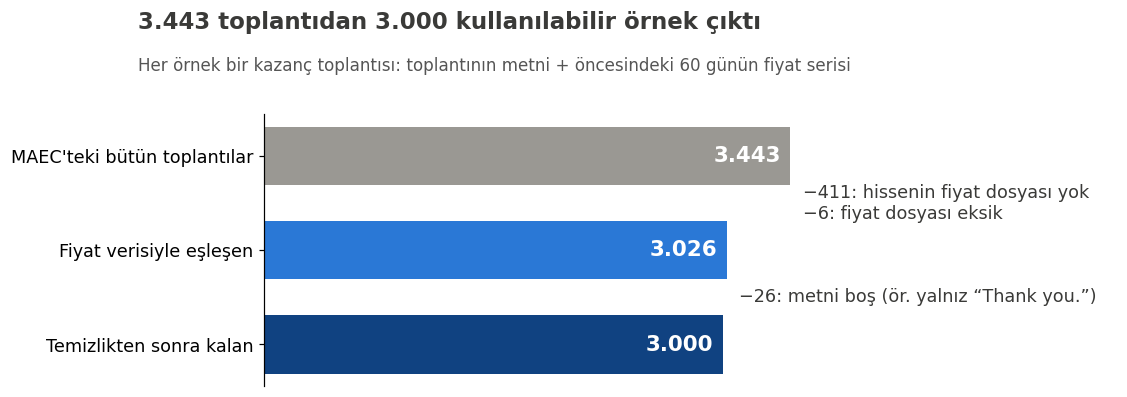

In [2]:
kayip = pd.read_csv(CIKTI / "veri_kaybi_tam_dokum.csv")
display(kayip)
bas, eslesen, son = kayip.kalan.iloc[0], kayip.kalan.iloc[3], kayip.kalan.iloc[-1]
fiyatsiz, kesik, bos = kayip.düşen.iloc[1], kayip.düşen.iloc[2] + kayip.düşen.iloc[3], kayip.düşen.iloc[-1]

fig, ax = plt.subplots(figsize=(10, 3.9))
etiketler = ["MAEC'teki bütün toplantılar", "Fiyat verisiyle eşleşen", "Temizlikten sonra kalan"]
degerler = [bas, eslesen, son]
renkler = [GRI, MAVI, "#104281"]
for i, (et, d_, r_) in enumerate(zip(etiketler, degerler, renkler)):
    ax.barh(2 - i, d_, color=r_, height=0.62)
    ax.text(d_ - 60, 2 - i, tr(d_), va="center", ha="right", color="white", fontsize=14, fontweight="bold")
ax.set_yticks([2, 1, 0], etiketler)
ax.set_xlim(0, bas * 1.62)
ax.text(bas + 80, 1.5, f"−{tr(fiyatsiz)}: hissenin fiyat dosyası yok\n−{tr(kesik)}: fiyat dosyası eksik", va="center", fontsize=11.5, color=KOYU)
ax.text(eslesen + 80, 0.5, f"−{tr(bos)}: metni boş (ör. yalnız “Thank you.”)", va="center", fontsize=11.5, color=KOYU)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
basliklar(fig, f"{tr(bas)} toplantıdan {tr(son)} kullanılabilir örnek çıktı",
          "Her örnek bir kazanç toplantısı: toplantının metni + öncesindeki 60 günün fiyat serisi")
kaydet(fig, "s01_veri_hunisi")
print("başlangıç", bas, "| eşleşen", eslesen, "| nihai", son, "| fiyatsız", fiyatsiz, "| kesik", kesik, "| boş metin", bos)

## 2. Sınıflar dengeli mi?

{'düşük': 1074, 'orta': 938, 'yüksek': 988} | toplam 3000


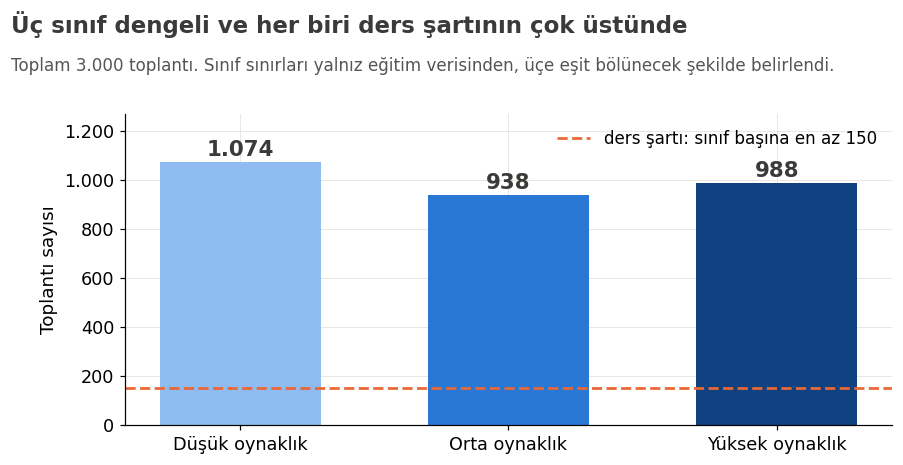

In [3]:
sd = pd.read_csv(CIKTI / "f2_sinif_dagilimi.csv", index_col=0)
n = sd.loc[["düşük", "orta", "yüksek"], "tümü"]
fig, ax = plt.subplots(figsize=(9, 4.3))
x = np.arange(3)
ax.bar(x, n.values, color=SINIF_RENK, width=0.6)
for xi, v_ in zip(x, n.values):
    ax.text(xi, v_ + 25, tr(v_), ha="center", fontsize=14, fontweight="bold", color=KOYU)
ax.axhline(150, color=TURUNCU, ls="--", lw=1.8, label="ders şartı: sınıf başına en az 150")
ax.legend(loc="upper right", frameon=False)
ax.set_xticks(x, ["Düşük oynaklık", "Orta oynaklık", "Yüksek oynaklık"])
ax.set_ylabel("Toplantı sayısı")
ax.yaxis.set_major_formatter(VIRGUL)
ax.set_ylim(0, n.max() * 1.18)
basliklar(fig, "Üç sınıf dengeli ve her biri ders şartının çok üstünde",
          f"Toplam {tr(n.sum())} toplantı. Sınıf sınırları yalnız eğitim verisinden, üçe eşit bölünecek şekilde belirlendi.")
kaydet(fig, "s02_siniflar")
print(n.to_dict(), "| toplam", n.sum())

## 3. Toplantı metinleri ne uzunlukta?

medyan 1953.5 | 1.000–4.000 arası %60.4 | en kısa 21 | en uzun 9081


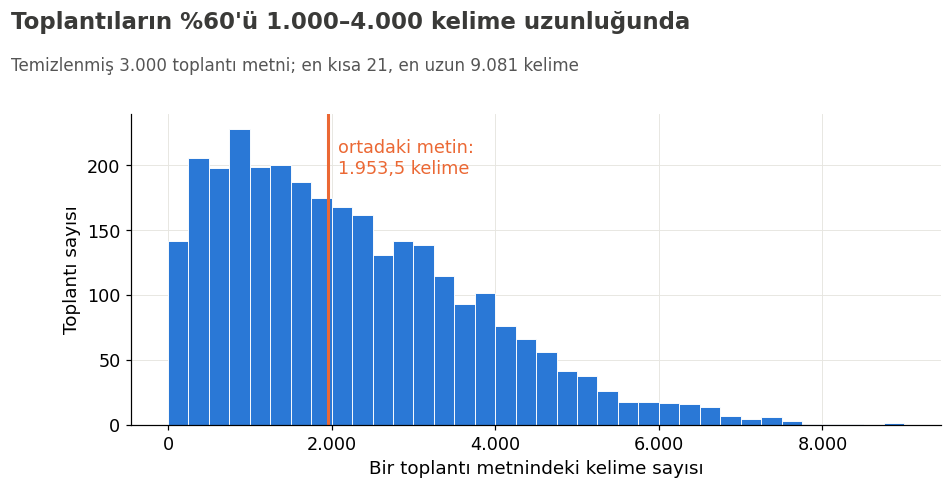

In [4]:
kel = tc.n_kelime_temiz
medyan = kel.median()
ara = ((kel >= 1000) & (kel <= 4000)).mean() * 100
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.hist(kel.clip(upper=9000), bins=np.arange(0, 9250, 250), color=MAVI, edgecolor="white", linewidth=0.6)
ax.axvline(medyan, color=TURUNCU, lw=2)
ax.text(medyan + 120, ax.get_ylim()[1] * 0.92, f"ortadaki metin:\n{tr(medyan, 1)} kelime", color=TURUNCU, fontsize=11.5, va="top")
ax.set_xlabel("Bir toplantı metnindeki kelime sayısı")
ax.set_ylabel("Toplantı sayısı")
ax.xaxis.set_major_formatter(VIRGUL)
basliklar(fig, f"Toplantıların %{tr(ara, 0)}'ü 1.000–4.000 kelime uzunluğunda",
          f"Temizlenmiş {tr(len(kel))} toplantı metni; en kısa {tr(kel.min())}, en uzun {tr(kel.max())} kelime")
kaydet(fig, "s03_metin_uzunlugu")
print(f"medyan {medyan} | 1.000–4.000 arası %{ara:.1f} | en kısa {kel.min()} | en uzun {kel.max()}")

## 4. Eşleşme doğru mu? Toplantı gününde fiyat sıçrıyor mu?

Notebook 01, Şekil 3 ile aynı hesap (geliştirme dönemi eşleşmiş çağrıları): her gün için hissenin ortalama mutlak getirisi.

sıradan gün %1.39 | gün 0 %3.81 | gün +1 %3.19 | oran 2.75 | n 1886


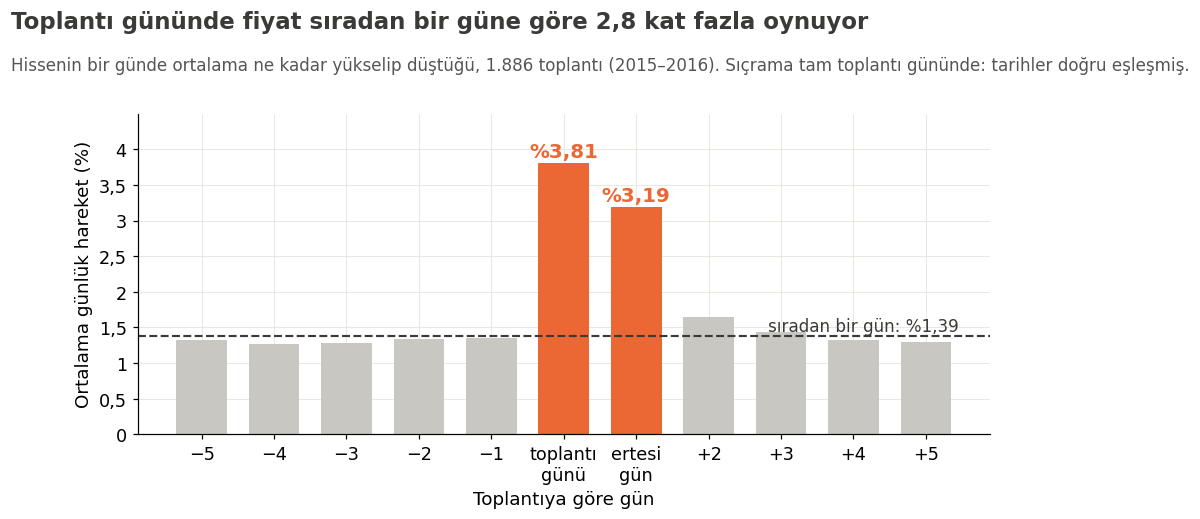

In [5]:
gelistirme = set(ce.loc[ce.tarih <= "2016-12-31", "klasor"])
pg = pen[pen.klasor.isin(gelistirme)]
ort = 100 * pg[pg.gun.between(-5, 5)].groupby("gun").getiri.apply(lambda s: s.abs().mean())
normal = 100 * pg[pg.gun.between(-60, -6)].getiri.abs().mean()
oran = ort.loc[0] / normal

fig, ax = plt.subplots(figsize=(10, 4.4))
renk = [TURUNCU if g in (0, 1) else "#c9c7c1" for g in ort.index]
ax.bar(ort.index, ort.values, color=renk, width=0.7)
ax.axhline(normal, color=KOYU, ls="--", lw=1.4)
ax.text(5.45, normal + 0.06, f"sıradan bir gün: %{tr(normal, 2)}", ha="right", fontsize=11, color=KOYU)
for g in (0, 1):
    ax.text(g, ort.loc[g] + 0.08, f"%{tr(ort.loc[g], 2)}", ha="center", fontsize=13, fontweight="bold", color=TURUNCU)
ax.set_xticks(ort.index, [("toplantı\ngünü" if g == 0 else "ertesi\ngün" if g == 1 else (f"+{g}" if g > 0 else tr(g))) for g in ort.index])
ax.set_xlabel("Toplantıya göre gün")
ax.set_ylabel("Ortalama günlük hareket (%)")
ax.yaxis.set_major_formatter(VIRGUL)
ax.set_ylim(0, ort.max() * 1.18)
basliklar(fig, f"Toplantı gününde fiyat sıradan bir güne göre {tr(oran, 1)} kat fazla oynuyor",
          f"Hissenin bir günde ortalama ne kadar yükselip düştüğü, {tr(pg.klasor.nunique())} toplantı (2015–2016). "
          "Sıçrama tam toplantı gününde: tarihler doğru eşleşmiş.")
kaydet(fig, "s04_olay_gunu")
print(f"sıradan gün %{normal:.2f} | gün 0 %{ort.loc[0]:.2f} | gün +1 %{ort.loc[1]:.2f} | oran {oran:.2f} | n {pg.klasor.nunique()}")

## 5. Bir örnek: aynı toplantının fiyatı ve metni

Seçim kuralı notebook 01 (Şekil 4) ile aynı: geliştirme döneminde yüksek sınıftan, şirket adı metinde geçen ve en az 800
kelimelik çağrılar arasından hedefi sınıf medyanına en yakın olan.

20150429_PKE | Faz 1 sınıfı 2 | nihai sınıf 2 | gün 0 değişim %7.6


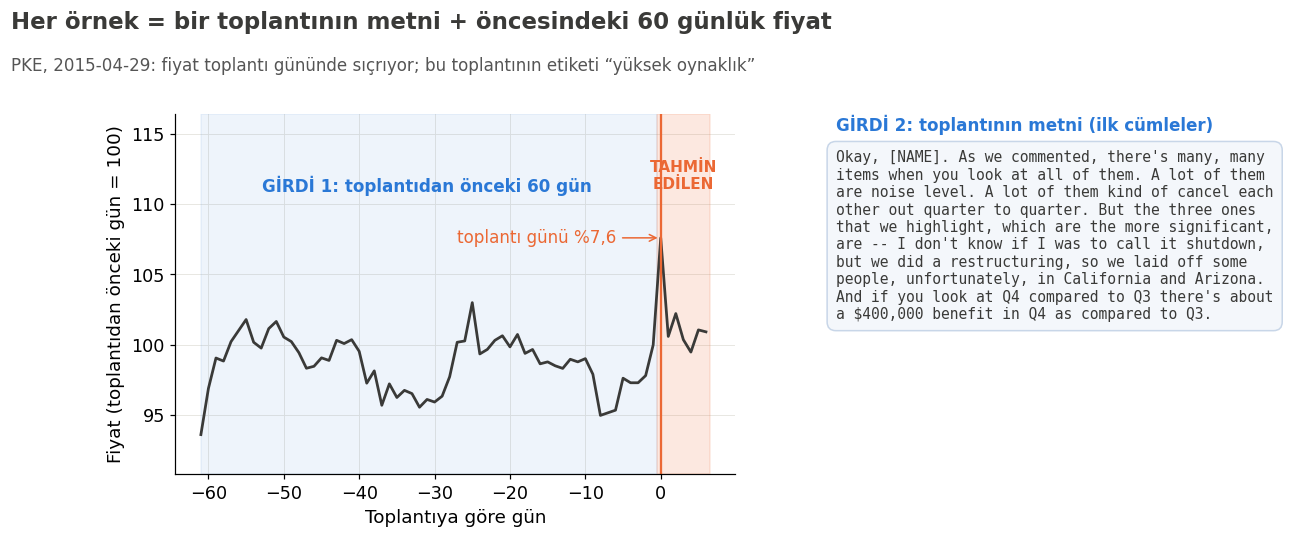

In [6]:
tg = ce[ce.tarih <= "2016-12-31"]
aday = tg[(tg.sinif == 2) & (tg.ad_geciyor == True) & (tg.n_kelime >= 800)]
k = (aday.v - tg[tg.sinif == 2].v.median()).abs().idxmin()
r = ce.loc[k]
son_sinif = int(tc.set_index("klasor").loc[r.klasor, "sinif"])
p_ = pen[(pen.klasor == r.klasor) & pen.gun.between(-61, 6)].set_index("gun")
fiyat = 100 * p_["adj close"] / p_.loc[-1, "adj close"]
r0 = 100 * (np.exp(p_.loc[0, "getiri"]) - 1)
cumleler = tc.set_index("klasor").loc[r.klasor, "cumleler_temiz"]
metin = textwrap.fill(" ".join(cumleler[:6]), 50)
satir = metin.splitlines()
metin = "\n".join(satir[:14]) + (" …" if len(satir) > 14 else "")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
a1.axvspan(-61, -0.5, color=MAVI, alpha=0.08)
a1.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.15)
a1.plot(fiyat.index, fiyat.values, color=KOYU, lw=1.8)
a1.axvline(0, color=TURUNCU, lw=1.5)
ust = fiyat.max() * 1.03
a1.text(-31, ust, "GİRDİ 1: toplantıdan önceki 60 gün", ha="center", fontsize=11, color=MAVI, fontweight="bold")
a1.text(3, ust, "TAHMİN\nEDİLEN", ha="center", fontsize=10, color=TURUNCU, fontweight="bold", va="bottom")
a1.annotate(f"toplantı günü %{tr(r0, 1)}", xy=(0, fiyat.loc[0]), xytext=(-27, fiyat.loc[0]),
            arrowprops=dict(arrowstyle="->", color=TURUNCU), fontsize=11, color=TURUNCU, va="center")
a1.set_ylim(fiyat.min() * 0.97, ust * 1.05)
a1.set_xlabel("Toplantıya göre gün")
a1.set_ylabel("Fiyat (toplantıdan önceki gün = 100)")
a1.yaxis.set_major_formatter(VIRGUL)
a2.axis("off")
a2.text(0, 1, "GİRDİ 2: toplantının metni (ilk cümleler)", fontsize=11, fontweight="bold", color=MAVI, va="top")
a2.text(0, 0.9, metin, fontsize=9.6, family="monospace", va="top", color=KOYU,
        bbox=dict(boxstyle="round,pad=0.6", fc="#f4f7fb", ec="#c8d6e8"))
basliklar(fig, "Her örnek = bir toplantının metni + öncesindeki 60 günlük fiyat",
          f"{r.ticker}, {r.tarih.date()}: fiyat toplantı gününde sıçrıyor; bu toplantının etiketi “{['düşük', 'orta', 'yüksek'][son_sinif]} oynaklık”")
kaydet(fig, "s05_ornek_toplanti")
print(r.klasor, "| Faz 1 sınıfı", r.sinif, "| nihai sınıf", son_sinif, f"| gün 0 değişim %{r0:.1f}")

## 6. Metin temizliği: önce ve sonra

Kural: nihai 3.000 çağrının 100–230 karakterlik ham cümleleri arasından en çok farklı gürültü türü içeren cümle
(eşitlikte en kısası). Yalnız metin (girdi) kullanılır.

,önce (metin),önce (toplam),sonra (toplam)
"dökümcü notu ([indiscernible], (ph) …)",634,1132,1
köşeli parantezli ekleme ([million] …),902,1867,6
URL,149,161,0
<UNK> (gizlenmiş kişi adı),2796,29465,0
tipografik karakter (’ – … •),194,4503,0
HTML varlığı (&amp; …),1,1,0


,önce,sonra,fark,değişim %
toplam kelime,6695821,6694353,-1468,-0.022
farklı kelime türü (küçük harf),45620,45603,-17,-0.037
cümle,346643,346585,-58,-0.017
karakter,38477126,38485234,8108,0.021


20171024_LMT | We won the ARTS – I believe it's ARTS 2D (sic) [ARTS-V2], which is sort of a radar threat emitter contract 
→ We won the ARTS - I believe it's ARTS 2D ARTS-V2, which is sort of a radar threat emitter contract


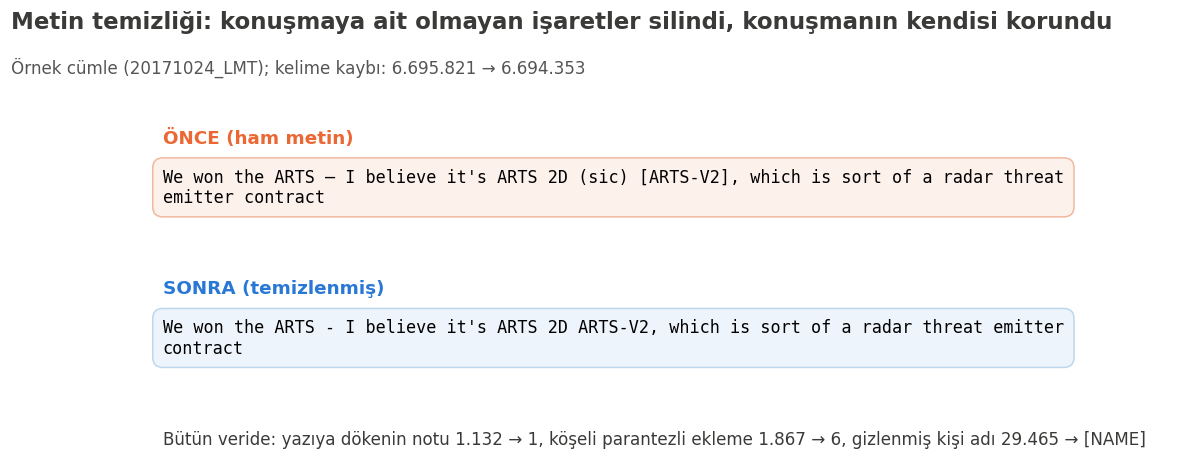

In [7]:
ham = veri.maec_oku().set_index("klasor").loc[tc.klasor, "cumleler"]
adaylar = []
for k_, cumleler in ham.items():
    for c in cumleler:
        if 100 <= len(c) <= 230:
            tur = sum(bool(d.search(c)) for d in temizle.KALIPLAR.values())
            if tur:
                adaylar.append((-tur, len(c), k_, c))
_, _, k_ornek, once = min(adaylar)
sonra = temizle.cumle_temizle(once)
gur = pd.read_csv(CIKTI / "f2_metin_gurultusu.csv", index_col=0)
olcu = pd.read_csv(CIKTI / "f2_metin_olculeri.csv", index_col=0)
display(gur)
display(olcu)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axis("off")
ax.text(0, 0.95, "ÖNCE (ham metin)", fontsize=12, fontweight="bold", color=TURUNCU, va="top")
ax.text(0, 0.82, textwrap.fill(once, 95), fontsize=11, family="monospace", va="top",
        bbox=dict(boxstyle="round,pad=0.6", fc="#fdf1ec", ec="#f2b89f"))
ax.text(0, 0.45, "SONRA (temizlenmiş)", fontsize=12, fontweight="bold", color=MAVI, va="top")
ax.text(0, 0.32, textwrap.fill(sonra, 95), fontsize=11, family="monospace", va="top",
        bbox=dict(boxstyle="round,pad=0.6", fc="#eef4fb", ec="#bdd7ee"))
ax.text(0, -0.05, (f"Bütün veride: yazıya dökenin notu {tr(gur.iloc[0, 1])} → {tr(gur.iloc[0, 2])}, köşeli parantezli ekleme "
                   f"{tr(gur.iloc[1, 1])} → {tr(gur.iloc[1, 2])}, gizlenmiş kişi adı {tr(gur.iloc[3, 1])} → [NAME]"),
        fontsize=11, color=KOYU, va="top")
basliklar(fig, "Metin temizliği: konuşmaya ait olmayan işaretler silindi, konuşmanın kendisi korundu",
          f"Örnek cümle ({k_ornek}); kelime kaybı: {tr(olcu.loc['toplam kelime'].iloc[0])} → {tr(olcu.loc['toplam kelime'].iloc[1])}")
kaydet(fig, "s06_metin_temizligi")
print(k_ornek, "|", once, "\n→", sonra)

## 7. Fiyat serisi: önce ve sonra

Kural: nihai 3.000 çağrı arasından girdi penceresinde (fiyat günleri −61..−1, notebook 02 ile aynı) ortalama fiyatı en düşük, ortanca ve en yüksek olan üç
çağrı. Yalnız girdi penceresi kullanılır.

{'20160503_LNTH': np.float64(1.98), '20170228_BLD': np.float64(37.41), '20171106_BKNG': np.float64(1869.43)} | oran 942.4


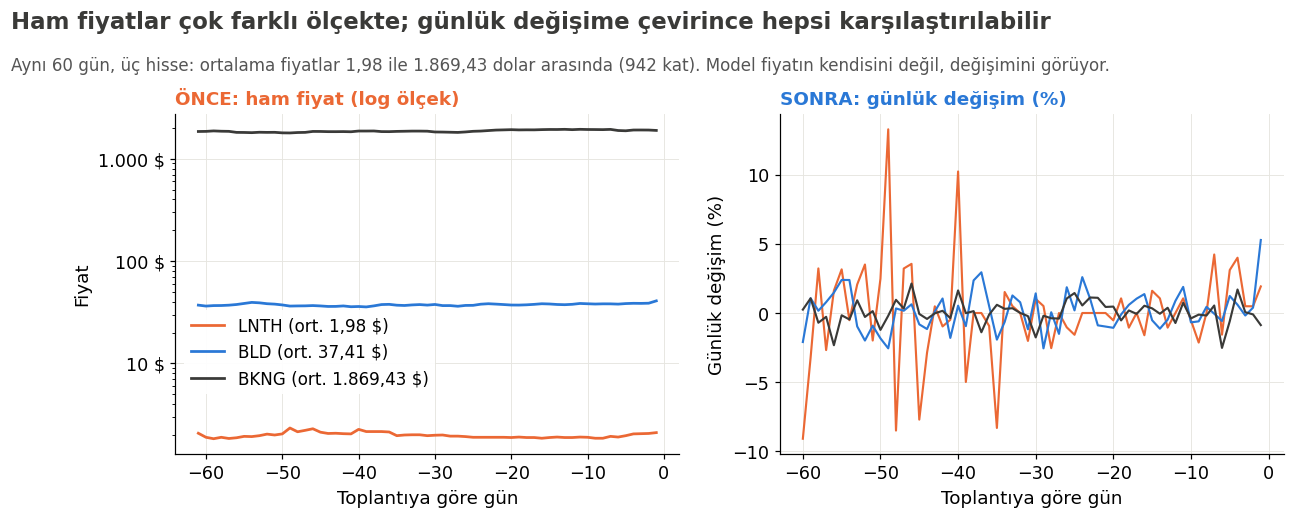

In [8]:
gp = pen[pen.klasor.isin(tc.klasor) & pen.gun.between(-61, -1)]          # notebook 02 ile aynı pencere
ort_fiyat = gp.groupby("klasor")["adj close"].mean()
sec = [ort_fiyat.idxmin(), (ort_fiyat - ort_fiyat.median()).abs().idxmin(), ort_fiyat.idxmax()]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
for k_, renk in zip(sec, [TURUNCU, MAVI, KOYU]):
    s_ = gp[gp.klasor == k_].set_index("gun")
    et = f"{k_.split('_')[1]} (ort. {tr(ort_fiyat[k_], 2)} $)"
    a1.plot(s_.index, s_["adj close"], color=renk, lw=1.8, label=et)
    a2.plot(s_.index, 100 * s_.getiri, color=renk, lw=1.4, label=et)
a1.set_yscale("log")
a1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{tr(x)} $" if x >= 1 else f"{x:g} $"))
a1.set_title("ÖNCE: ham fiyat (log ölçek)", loc="left", fontsize=12, fontweight="bold", color=TURUNCU)
a1.set_ylabel("Fiyat")
a2.set_title("SONRA: günlük değişim (%)", loc="left", fontsize=12, fontweight="bold", color=MAVI)
a2.set_ylabel("Günlük değişim (%)")
a2.yaxis.set_major_formatter(VIRGUL)
for a in (a1, a2):
    a.set_xlabel("Toplantıya göre gün")
a1.legend(loc="center left", bbox_to_anchor=(0, 0.3), frameon=True, framealpha=0.95, edgecolor="none")
basliklar(fig, "Ham fiyatlar çok farklı ölçekte; günlük değişime çevirince hepsi karşılaştırılabilir",
          f"Aynı 60 gün, üç hisse: ortalama fiyatlar {tr(ort_fiyat.min(), 2)} ile {tr(ort_fiyat.max(), 2)} dolar arasında ({tr(ort_fiyat.max() / ort_fiyat.min())} kat). "
          "Model fiyatın kendisini değil, değişimini görüyor.")
kaydet(fig, "s07_fiyat_olcegi")
print({k_: round(ort_fiyat[k_], 2) for k_ in sec}, "| oran", round(ort_fiyat.max() / ort_fiyat.min(), 1))

## 8. Fiyat geçmişi: önceden çok oynayan hisse sonra da çok oynuyor mu?

Geliştirme dönemi (1.866 çağrı). Toplantı öncesi 60 günde günlük getirinin standart sapması (= hissenin tipik günlük
hareketi, %); her sınıfta ortanca değer.

{0: 1.343000054359436, 1: 1.6740000247955322, 2: 2.0429999828338623}


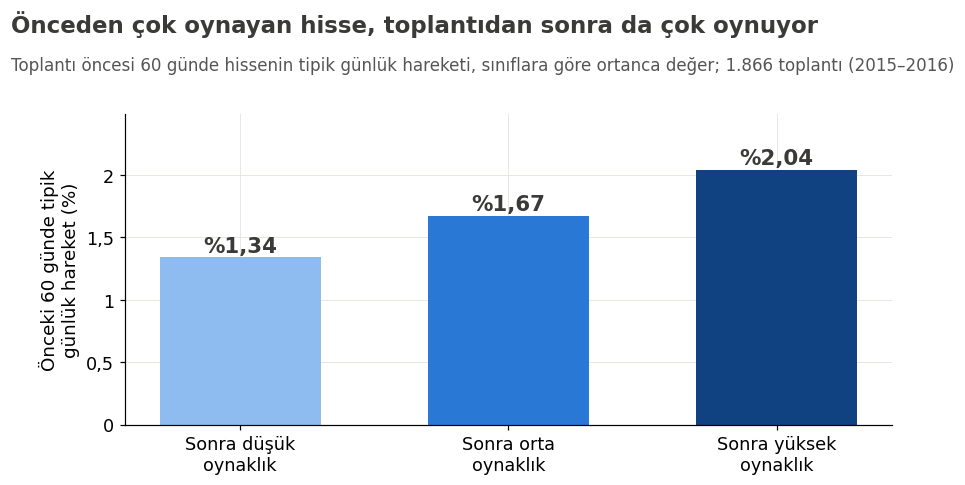

In [9]:
tipik = 100 * np.exp(e.gecmis_oyn_60)
med = tipik.groupby(e.sinif).median()
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(range(3), med.values, color=SINIF_RENK, width=0.6)
for i, v_ in enumerate(med.values):
    ax.text(i, v_ + 0.04, f"%{tr(v_, 2)}", ha="center", fontsize=14, fontweight="bold", color=KOYU)
ax.set_xticks(range(3), ["Sonra düşük\noynaklık", "Sonra orta\noynaklık", "Sonra yüksek\noynaklık"])
ax.set_ylabel("Önceki 60 günde tipik\ngünlük hareket (%)")
ax.yaxis.set_major_formatter(VIRGUL)
ax.set_ylim(0, med.max() * 1.22)
basliklar(fig, "Önceden çok oynayan hisse, toplantıdan sonra da çok oynuyor",
          f"Toplantı öncesi 60 günde hissenin tipik günlük hareketi, sınıflara göre ortanca değer; {tr(len(e))} toplantı (2015–2016)")
kaydet(fig, "s08_fiyat_ipucu")
print(med.round(3).to_dict())

## 9. Konuşmanın tonu sınıfları ayırıyor mu?

Geliştirme dönemi. Loughran–McDonald finans sözlüğüyle 1.000 kelimedeki olumlu ve olumsuz kelime sayısı; sınıf ortalaması.

       olumlu  olumsuz
sinif                 
0       14.42     7.28
1       14.66     6.75
2       14.55     7.20


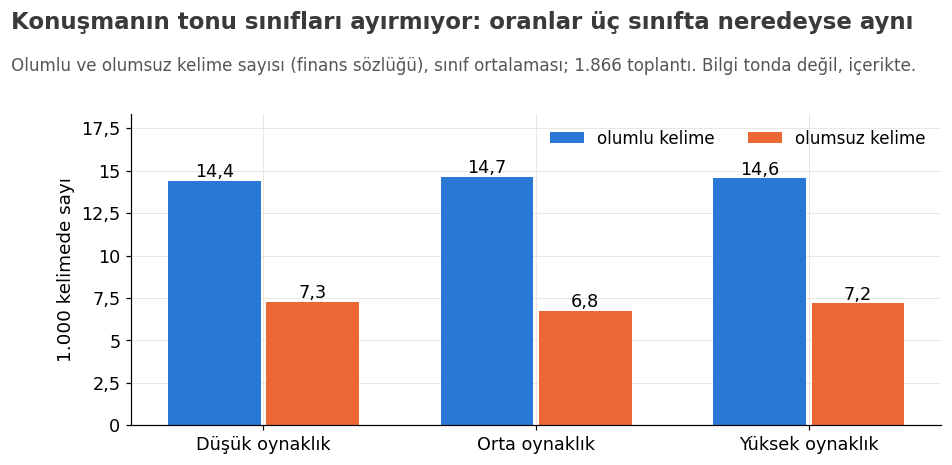

In [10]:
ton = e.groupby("sinif")[["olumlu", "olumsuz"]].mean()
fig, ax = plt.subplots(figsize=(9.5, 4.3))
x = np.arange(3)
ax.bar(x - 0.18, ton.olumlu, width=0.34, color=MAVI, label="olumlu kelime")
ax.bar(x + 0.18, ton.olumsuz, width=0.34, color=TURUNCU, label="olumsuz kelime")
for xi, (o1, o2) in zip(x, ton.values):
    ax.text(xi - 0.18, o1 + 0.2, tr(o1, 1), ha="center", fontsize=11.5)
    ax.text(xi + 0.18, o2 + 0.2, tr(o2, 1), ha="center", fontsize=11.5)
ax.set_xticks(x, ["Düşük oynaklık", "Orta oynaklık", "Yüksek oynaklık"])
ax.set_ylabel("1.000 kelimede sayı")
ax.yaxis.set_major_formatter(VIRGUL)
ax.set_ylim(0, ton.values.max() * 1.25)
ax.legend(frameon=False, loc="upper right", ncol=2)
basliklar(fig, "Konuşmanın tonu sınıfları ayırmıyor: oranlar üç sınıfta neredeyse aynı",
          f"Olumlu ve olumsuz kelime sayısı (finans sözlüğü), sınıf ortalaması; {tr(len(e))} toplantı. Bilgi tonda değil, içerikte.")
kaydet(fig, "s09_ton")
print(ton.round(2))

## 10. Metin, fiyatın göremediğini görüyor mu?

Notebook 03, Şekil 21 ile aynı hesap. **Metin sinyali:** toplantı metnine en çok benzeyen 10 başka şirketin toplantısındaki
oynaklığın ortalaması (TF-IDF benzerliği). Toplantılar önce fiyat geçmişine, sonra metin sinyaline göre üç eşit gruba ayrılır.

gecmis_t,düşük,orta,yüksek
komsu_t,,,
düşük,8.1,20.0,50.0
orta,14.4,33.2,51.4
yüksek,22.3,43.8,58.7


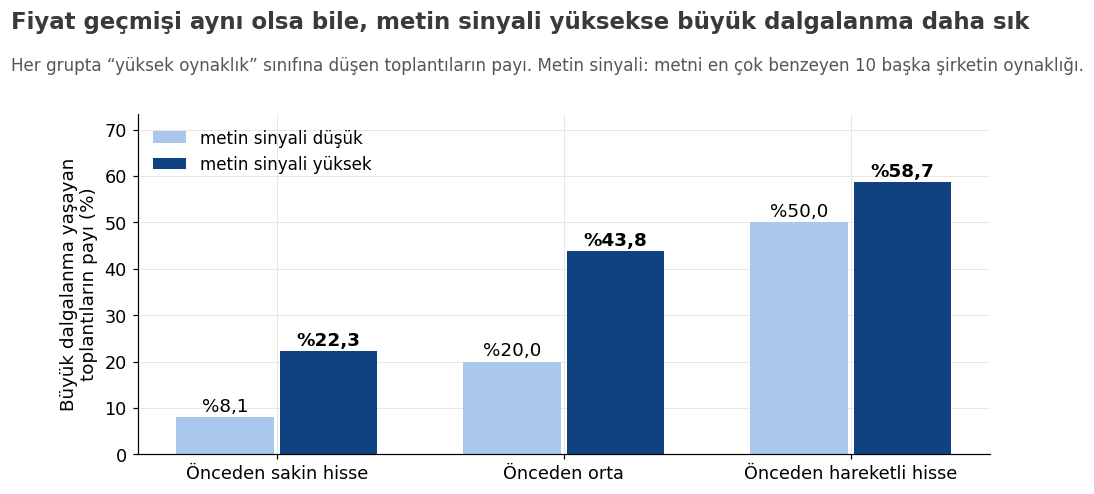

In [11]:
e["gecmis_t"] = pd.qcut(e.gecmis_oyn_60, 3, labels=["düşük", "orta", "yüksek"])
e["komsu_t"] = pd.qcut(e.komsu_v, 3, labels=["düşük", "orta", "yüksek"])
pay = e.assign(yuksek=(e.sinif == 2)).pivot_table(index="komsu_t", columns="gecmis_t", values="yuksek", aggfunc="mean", observed=False) * 100
display(pay.round(1))
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(3)
ax.bar(x - 0.18, pay.loc["düşük"], width=0.34, color="#a9c8ec", label="metin sinyali düşük")
ax.bar(x + 0.18, pay.loc["yüksek"], width=0.34, color="#104281", label="metin sinyali yüksek")
for xi, (a_, b_) in zip(x, zip(pay.loc["düşük"], pay.loc["yüksek"])):
    ax.text(xi - 0.18, a_ + 1.2, f"%{tr(a_, 1)}", ha="center", fontsize=12)
    ax.text(xi + 0.18, b_ + 1.2, f"%{tr(b_, 1)}", ha="center", fontsize=12, fontweight="bold")
ax.set_xticks(x, ["Önceden sakin hisse", "Önceden orta", "Önceden hareketli hisse"])
ax.set_ylabel("Büyük dalgalanma yaşayan\ntoplantıların payı (%)")
ax.set_ylim(0, pay.values.max() * 1.25)
ax.yaxis.set_major_formatter(VIRGUL)
ax.legend(frameon=False, loc="upper left")
basliklar(fig, "Fiyat geçmişi aynı olsa bile, metin sinyali yüksekse büyük dalgalanma daha sık",
          "Her grupta “yüksek oynaklık” sınıfına düşen toplantıların payı. Metin sinyali: metni en çok benzeyen 10 başka şirketin oynaklığı.")
kaydet(fig, "s10_metin_ve_fiyat")

## 11. İki gerçek örnek: birini metin, diğerini fiyat haber veriyordu

Seçim kuralı notebook 03 (Şekil 24) ile aynı: **uç** = en yüksek hedef oynaklıklı çağrı; **çelişkili** = geçmiş oynaklığa göre
beklenenden en çok sapan çağrı. Sıra: 1.866 geliştirme çağrısı içinde yüzde kaçının üstünde olduğu.

celiskili 20150728_BGFV | sıra geçmiş 47 | sıra metin 97 | gün 1: %-29.4
uc 20151106_LXU | sıra geçmiş 96 | sıra metin 58 | gün 0: %-44.0


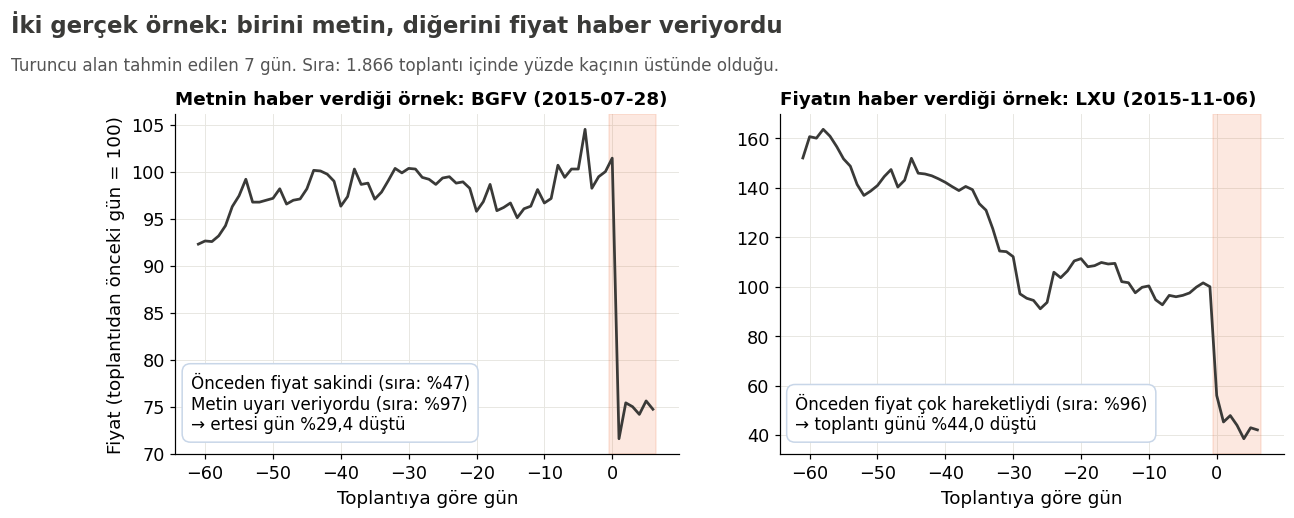

In [12]:
sira = lambda s: (s.rank(pct=True) * 100).round().astype(int)
e["sira_gecmis"], e["sira_metin"] = sira(e.gecmis_oyn_60), sira(e.komsu_v)
vakalar = [("celiskili", e.artik.idxmax()), ("uc", e.v.idxmax())]
fig, eksen = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (tur, i) in zip(eksen, vakalar):
    r = e.loc[i]
    p_ = pen[(pen.klasor == r.klasor) & pen.gun.between(-61, 6)].set_index("gun")
    fiyat = 100 * p_["adj close"] / p_.loc[-1, "adj close"]
    hedef = p_.loc[0:6, "getiri"]
    g = int(hedef.abs().idxmax())
    deg = 100 * (np.exp(hedef.loc[g]) - 1)
    ax.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.15)
    ax.plot(fiyat.index, fiyat.values, color=KOYU, lw=1.8)
    gun_ad = "toplantı günü" if g == 0 else "ertesi gün" if g == 1 else f"gün +{g}"
    if tur == "celiskili":
        not_ = (f"Önceden fiyat sakindi (sıra: %{r.sira_gecmis})\nMetin uyarı veriyordu (sıra: %{r.sira_metin})\n"
                f"→ {gun_ad} %{tr(abs(deg), 1)} düştü")
        ad = "Metnin haber verdiği örnek"
    else:
        not_ = f"Önceden fiyat çok hareketliydi (sıra: %{r.sira_gecmis})\n→ {gun_ad} %{tr(abs(deg), 1)} düştü"
        ad = "Fiyatın haber verdiği örnek"
    ax.set_title(f"{ad}: {r.ticker} ({r.tarih.date()})", loc="left", fontsize=12, fontweight="bold")
    ax.text(0.03, 0.06, not_, transform=ax.transAxes, fontsize=11, va="bottom",
            bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#c8d6e8"))
    ax.set_xlabel("Toplantıya göre gün")
    ax.yaxis.set_major_formatter(VIRGUL)
    print(tur, r.klasor, "| sıra geçmiş", r.sira_gecmis, "| sıra metin", r.sira_metin, f"| gün {g}: %{deg:.1f}")
eksen[0].set_ylabel("Fiyat (toplantıdan önceki gün = 100)")
basliklar(fig, "İki gerçek örnek: birini metin, diğerini fiyat haber veriyordu",
          "Turuncu alan tahmin edilen 7 gün. Sıra: 1.866 toplantı içinde yüzde kaçının üstünde olduğu.")
kaydet(fig, "s11_ornek_olaylar")

## 12. Veri bölme

geliştirme 1866 | test 1134 | gruplar {0: 375, 1: 372, 2: 374, 3: 373, 4: 372}


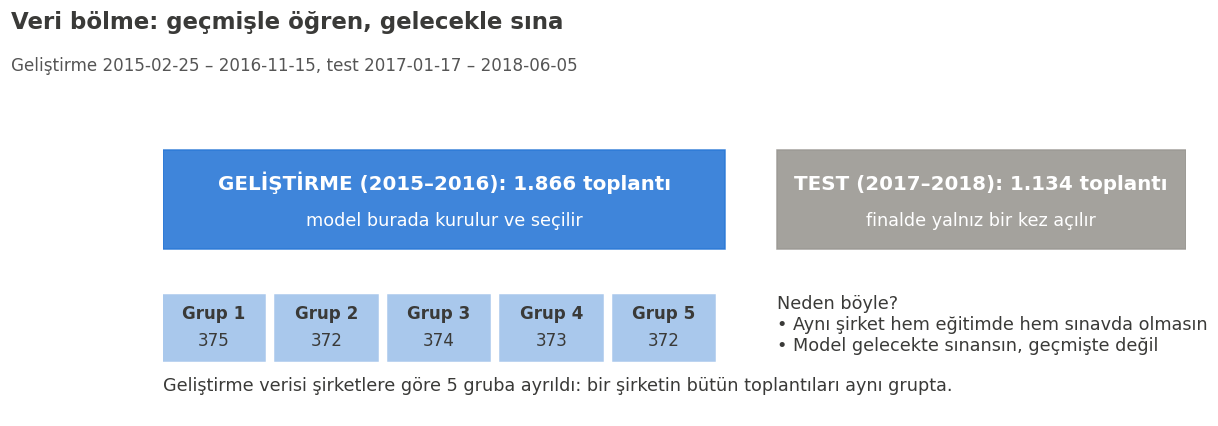

In [13]:
gel, tst = bolme[bolme.bolum == "gelistirme"], bolme[bolme.bolum == "test"]
kat_n = gel.kat.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axis("off")
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.add_patch(Rectangle((0, 55), 55, 33, color=MAVI, alpha=0.9))
ax.text(27.5, 75, f"GELİŞTİRME (2015–2016): {tr(len(gel))} toplantı", ha="center", color="white", fontsize=13, fontweight="bold")
ax.text(27.5, 63, "model burada kurulur ve seçilir", ha="center", color="white", fontsize=11.5)
ax.add_patch(Rectangle((60, 55), 40, 33, color=GRI, alpha=0.9))
ax.text(80, 75, f"TEST (2017–2018): {tr(len(tst))} toplantı", ha="center", color="white", fontsize=13, fontweight="bold")
ax.text(80, 63, "finalde yalnız bir kez açılır", ha="center", color="white", fontsize=11.5)
for j, (kat, sayi) in enumerate(kat_n.items()):
    ax.add_patch(Rectangle((j * 11, 18), 10, 22, color="#a9c8ec"))
    ax.text(j * 11 + 5, 32, f"Grup {kat + 1}", ha="center", fontsize=11, fontweight="bold", color=KOYU)
    ax.text(j * 11 + 5, 23, tr(sayi), ha="center", fontsize=11, color=KOYU)
ax.text(0, 8, "Geliştirme verisi şirketlere göre 5 gruba ayrıldı: bir şirketin bütün toplantıları aynı grupta.",
        fontsize=11.5, color=KOYU)
ax.text(60, 30, "Neden böyle?\n• Aynı şirket hem eğitimde hem sınavda olmasın\n• Model gelecekte sınansın, geçmişte değil",
        fontsize=11.5, color=KOYU, va="center")
basliklar(fig, "Veri bölme: geçmişle öğren, gelecekle sına",
          f"Geliştirme {gel.tarih.min().date()} – {gel.tarih.max().date()}, test {tst.tarih.min().date()} – {tst.tarih.max().date()}")
kaydet(fig, "s12_bolme")
print("geliştirme", len(gel), "| test", len(tst), "| gruplar", kat_n.to_dict())